## Assignment: $k$ Means Clustering


**Q1.** This is a question about clustering. We want to investigate how adjusting the "noisiness" of the data impacts the quality of the algorithm and the difficulty of picking $k$.

1. Run the code below, which creates four datasets: `df0_125`, `df0_25`, `df0_5`, `df1_0`, and `df2_0`. Each data set is created by increasing the amount of `noise` (standard deviation) around the cluster centers, from `0.125` to `0.25` to `0.5` to `1.0` to `2.0`.

```
import numpy as np
import pandas as pd

def createData(noise,N=50):
    np.random.seed(100) # Set the seed for replicability
    # Generate (x1,x2,g) triples:
    X1 = np.array([np.random.normal(1,noise,N),np.random.normal(1,noise,N)])
    X2 = np.array([np.random.normal(3,noise,N),np.random.normal(2,noise,N)])
    X3 = np.array([np.random.normal(5,noise,N),np.random.normal(3,noise,N)])
    # Concatenate into one data frame
    gdf1 = pd.DataFrame({'x1':X1[0,:],'x2':X1[1,:],'group':'a'})
    gdf2 = pd.DataFrame({'x1':X2[0,:],'x2':X2[1,:],'group':'b'})
    gdf3 = pd.DataFrame({'x1':X3[0,:],'x2':X3[1,:],'group':'c'})
    df = pd.concat([gdf1,gdf2,gdf3],axis=0)
    return df

df0_125 = createData(0.125)
df0_25 = createData(0.25)
df0_5 = createData(0.5)
df1_0 = createData(1.0)
df2_0 = createData(2.0)
```

2. Make scatterplots of the $(X1,X2)$ points by group for each of the datasets. As the `noise` goes up from 0.125 to 2.0, what happens to the visual distinctness of the clusters?
3. Create a scree plot for each of the datasets. Describe how the level of `noise` affects the scree plot (particularly the presence of a clear "elbow") and your ability to definitively select a $k$. (Pay attention to the vertical axis across plots, or put all the scree curves on a single canvas.)
4. Explain the intuition of the elbow, using this numerical simulation as an example.

**Q2.** This question is a case study on clustering.

1. Load the `SIPRI Military Expenditure Database.csv` file in the `./data` folder. This has data about military spending by country. Filter the rows to select only the year 2020, and drop all rows with missing values. I ended up with 148 countries. Is any further cleaning of the variables required?
2. Max-min normalize `Spending (2020 USD)` and `Spending per Capita`. Use a scree plot to determine the optimal number of clusters for the $k$ means clustering algorithm. Make a scatter plot of `Spending (2020 USD)` and `Spending per Capita`, and hue the dots by their cluster membership. Compute a describe table conditional on cluster membership (i.e. `.groupby(cluster).describe()`). What do you see? Where is the United States? Do you notice any patterns in the cluster membership?
3. Repeat part 2 for `Percent of Government Spending` and `Percent of GDP`. How do your results compare to part 2?
4. Use $k$ means clustering with all four numeric variables: `Spending (2020 USD)`, `Spending per Capita`, `Percent of Government Spending`, and `Percent of GDP`. How do your results compare to the previous two parts? 
5. Did the $k$-MC algorithm find any useful patterns for you in analyzing the spending?

---

## *Phase 1: Solution without AI

Complete all questions in the following cells without generative AI. Then commit and push the
notebook before beginning Phase 2.

**Declaration:** I completed this version without generative AI.

**Student(s):** Geethan Sundaram

**Date:** 10/12/2026

In [6]:
# Your Phase 1 solution to the problem goes here.
import numpy as np
import pandas as pd

print("-- Q1.1 - Create Datasets --")

def createData(noise,N=50):
    np.random.seed(100) # Set the seed for replicability
    # Generate (x1,x2,g) triples:
    X1 = np.array([np.random.normal(1,noise,N),np.random.normal(1,noise,N)])
    X2 = np.array([np.random.normal(3,noise,N),np.random.normal(2,noise,N)])
    X3 = np.array([np.random.normal(5,noise,N),np.random.normal(3,noise,N)])
    # Concatenate into one data frame
    gdf1 = pd.DataFrame({'x1':X1[0,:],'x2':X1[1,:],'group':'a'})
    gdf2 = pd.DataFrame({'x1':X2[0,:],'x2':X2[1,:],'group':'b'})
    gdf3 = pd.DataFrame({'x1':X3[0,:],'x2':X3[1,:],'group':'c'})
    df = pd.concat([gdf1,gdf2,gdf3],axis=0)
    return df

df0_125 = createData(0.125)
df0_25 = createData(0.25)
df0_5 = createData(0.5)
df1_0 = createData(1.0)
df2_0 = createData(2.0)

print(df0_125.head())
print(df0_25.head())
print(df0_5.head())
print(df1_0.head())
print(df2_0.head())

# Put datasets into dictionary
datasets = {
    0.125: df0_125,
    0.25: df0_25,
    0.5: df0_5,
    1.0: df1_0,
    2.0: df2_0
}

-- Q1.1 - Create Datasets --
         x1        x2 group
0  0.781279  0.851498     a
1  1.042835  0.931282     a
2  1.144129  0.882494     a
3  0.968445  0.896508     a
4  1.122665  1.013608     a
         x1        x2 group
0  0.562559  0.702996     a
1  1.085670  0.862563     a
2  1.288259  0.764988     a
3  0.936891  0.793017     a
4  1.245330  1.027216     a
         x1        x2 group
0  0.125117  0.405991     a
1  1.171340  0.725127     a
2  1.576518  0.529977     a
3  0.873782  0.586034     a
4  1.490660  1.054432     a
         x1        x2 group
0 -0.749765 -0.188018     a
1  1.342680  0.450254     a
2  2.153036  0.059954     a
3  0.747564  0.172068     a
4  1.981321  1.108863     a
         x1        x2 group
0 -2.499531 -1.376035     a
1  1.685361 -0.099492     a
2  3.306072 -0.880092     a
3  0.495128 -0.655865     a
4  2.962642  1.217727     a


-- Q1.2 - Scatterplots of (X1,X2) points by group for each dataset --


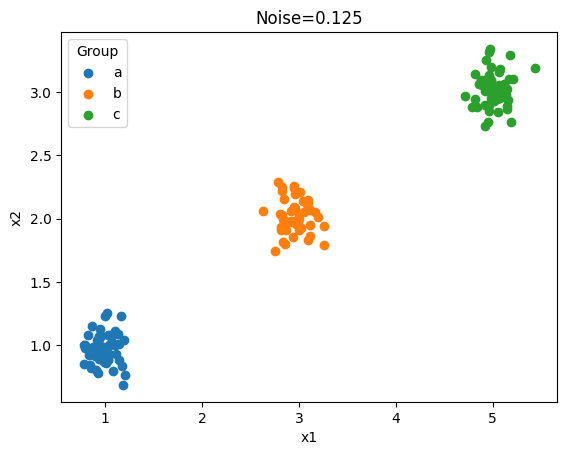

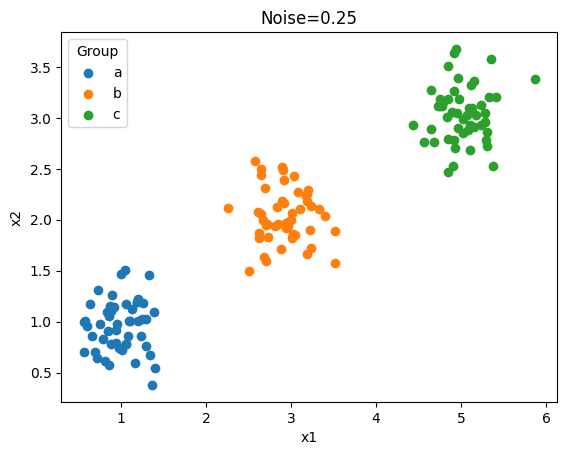

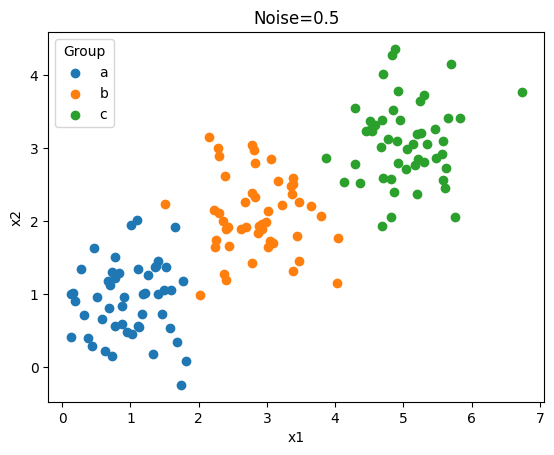

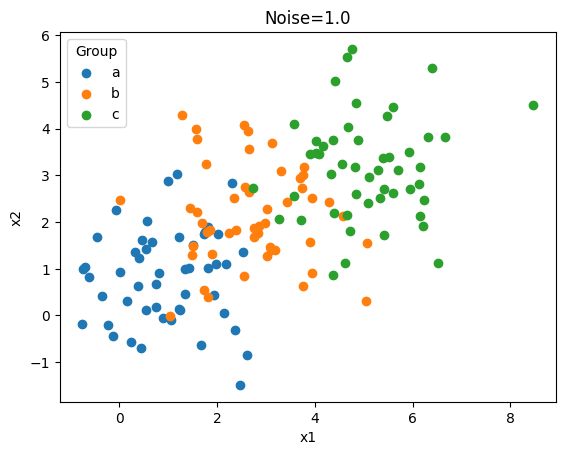

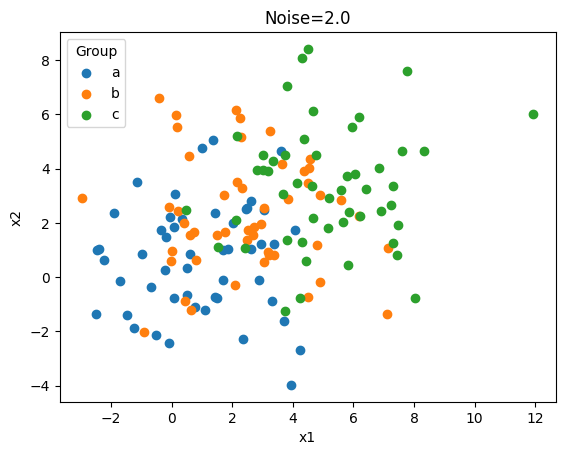

As the noise increases, the clusters become much less distinct and isolated and
the points from the different clusters start to overlap. This makes it way
harder to properly identify the clusters and what separates them.


In [ ]:
import matplotlib.pyplot as plt
import textwrap
from sklearn.cluster import KMeans

print("-- Q1.2 - Scatterplots of (X1,X2) points by group for each dataset --")

# Create scatterplots of (X1,X2) points by group for each dataset
for noise, df in datasets.items():
    colors = {'a': 'tab:blue', 'b': 'tab:orange', 'c': 'tab:green'}
    
    for group, group_df in df.groupby('group'):
        plt.scatter(
            group_df['x1'],
            group_df['x2'],
            color=colors[group],
            label=group
        )

    plt.title(f'Noise={noise}')
    plt.xlabel('x1')
    plt.ylabel('x2')
    plt.legend(title='Group')
    plt.show()

text = "As the noise increases, the clusters become much less distinct and isolated and the points from the different clusters start to overlap. This makes it way harder to properly identify the clusters and what separates them."
print("\n".join(textwrap.wrap(text, width=80)))

-- Q1.3 - Scree plots --


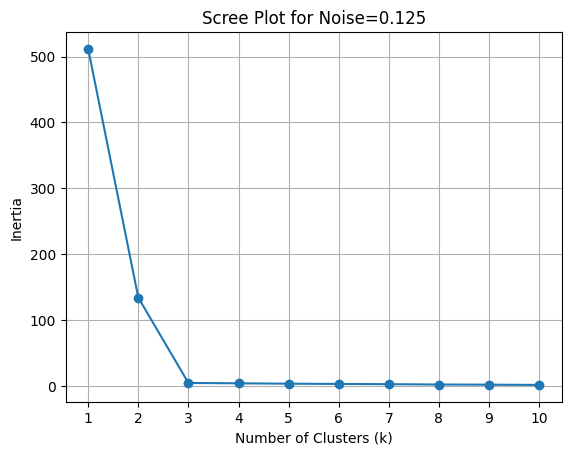

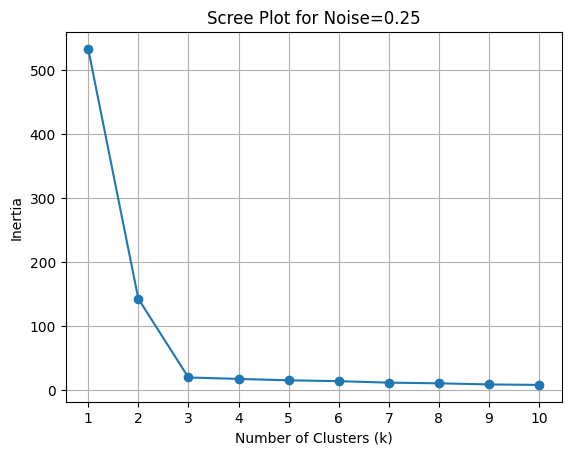

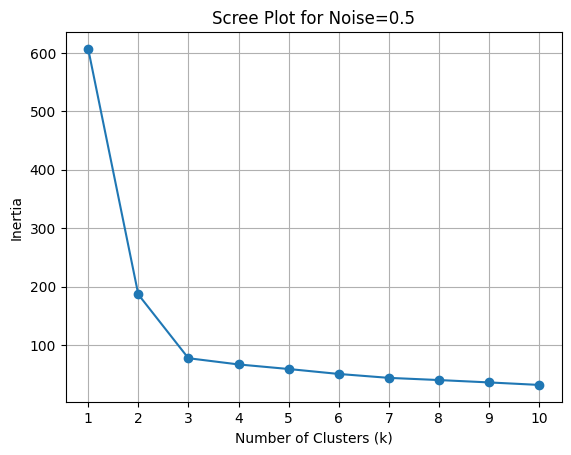

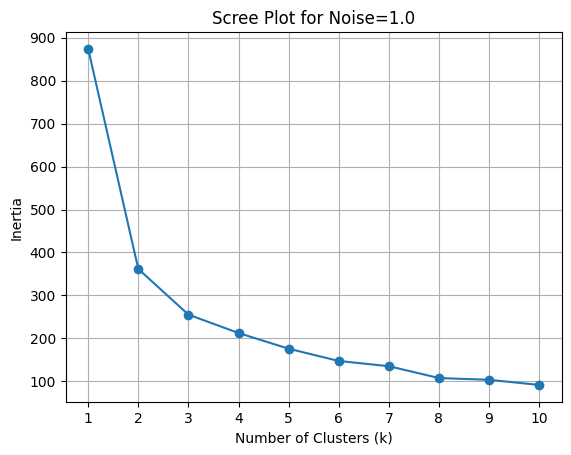

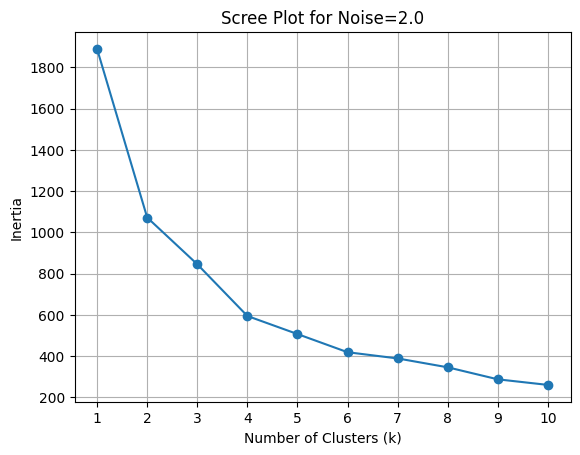

As the noise increases, the scree plots the elbow becomes less noticeable and
the inertia values decreases in a more gradual fashion. The inertia values are
also higher with higher noise levels, which indicates that clusters are less
compact and more spread out instead. Once again, this makes it difficult to
determine the optimal number of clusters without a clear elbow. For selecting a
k-value, it becomes more subjective and less reliable as the noise increases,
since the elbow is used for determining what the k-value is.


In [ ]:
print("-- Q1.3 - Scree plots --")

# Create scree plots for each dataset
for noise, df in datasets.items():
    X = df[['x1', 'x2']].values
    inertia = []
    k_values = range(1, 11)

    for k in k_values:
        kmeans = KMeans(n_clusters=k, random_state=100)
        kmeans.fit(X)
        inertia.append(kmeans.inertia_)

    plt.plot(k_values, inertia, marker='o')
    plt.title(f'Scree Plot for Noise={noise}')
    plt.xlabel('Number of Clusters (k)')
    plt.ylabel('Inertia')
    plt.xticks(k_values)
    plt.grid()
    plt.show()

text = "As the noise increases, the scree plots the elbow becomes less noticeable and the inertia values decreases in a more gradual fashion. The inertia values are also higher with higher noise levels, which indicates that clusters are less compact and more spread out instead. Once again, this makes it difficult to determine the optimal number of clusters without a clear elbow. For selecting a k-value, it becomes more subjective and less reliable as the noise increases, since the elbow is used for determining what the k-value is."

print("\n".join(textwrap.wrap(text, width=80)))

In [25]:
print("-- Q1.4 - Intuition of elbow --")

text = "The SSE (sum of squared errors) is a measure of how well the clusters fit the data, and the elbow point represents the point where adding more clusters does not significantly improve the fit. The elbow is the point on the screen plot where inertia starts to decrease at a slower rate. It is when the marginal gain of adding another cluster is not worth the cost of adding another cluster. The elbow is used to determine the optimal number of clusters because it represents a balance between having too few clusters (which may miss the underlying structure of the data) and having too many clusters (which may lead to overfiting and increased complexity).\n\nIn the above example, the elbow point is at k=3 for the lower noise levels, which corresponds to the three distinct clusters in the data. As the noise increases, the elbow becomes less clear and it becomes more difficult to determine the optimal number of clusters."

print("\n".join(textwrap.wrap(text, width=80)))

-- Q1.4 - Intuition of elbow --
The SSE (sum of squared errors) is a measure of how well the clusters fit the
data, and the elbow point represents the point where adding more clusters does
not significantly improve the fit. The elbow is the point on the screen plot
where inertia starts to decrease at a slower rate. It is when the marginal gain
of adding another cluster is not worth the cost of adding another cluster. The
elbow is used to determine the optimal number of clusters because it represents
a balance between having too few clusters (which may miss the underlying
structure of the data) and having too many clusters (which may lead to
overfiting and increased complexity).


In [ ]:
import seaborn as sns
from sklearn.cluster import KMeans
from sklearn.preprocessing import MinMaxScaler

print("-- Q2.1 - Loading the data --")

# load the data
df = pd.read_csv('data/SIPRI Military Expenditure Database.csv')

# clean the column names
df.columns = df.columns.str.strip()

# convert the Year column to numeric and filter for 2020
df["Year"] = pd.to_numeric(df["Year"], errors="coerce")
df = df[df["Year"] == 2020].copy()

cols = [
    "Spending (2020 USD)",
    "Spending per Capita",
    "Percent of Government Spending",
    "Percent of GDP"
]

# clean the data
for col in cols:
    df[col] = df[col].astype(str).str.replace(",", "", regex=False)
    df[col] = df[col].str.replace("$", "", regex=False)
    df[col] = df[col].str.replace("%", "", regex=False)
    df[col] = pd.to_numeric(df[col], errors="coerce")

df = df.dropna().reset_index(drop=True)

print(df.head())

print(df['Country'].value_counts())

-- Q2.1 - Loading the data --
   index  Year      Country  Spending (2020 USD)  Percent of GDP  \
0     32  2020  Afghanistan           279.576955        0.013589   
1     66  2020      Albania           187.433234        0.012583   
2    100  2020      Algeria          9708.277440        0.066600   
3    134  2020       Angola           993.594405        0.014442   
4    168  2020    Argentina          2830.929705        0.007269   

   Percent of Government Spending  Spending per Capita  
0                        0.049728             7.181899  
1                        0.037952            65.126211  
2                        0.173924           221.392384  
3                        0.074624            30.231680  
4                        0.017268            62.636731  
Country
Afghanistan    1
Montenegro     1
Mozambique     1
Myanmar        1
Namibia        1
              ..
Gambia, The    1
Georgia        1
Germany        1
Ghana          1
Zimbabwe       1
Name: count, Length: 148

-- Q2.2 - Determine optimal k for spending --


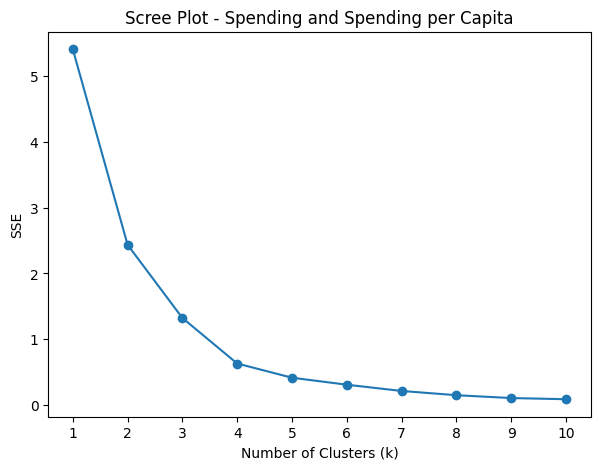

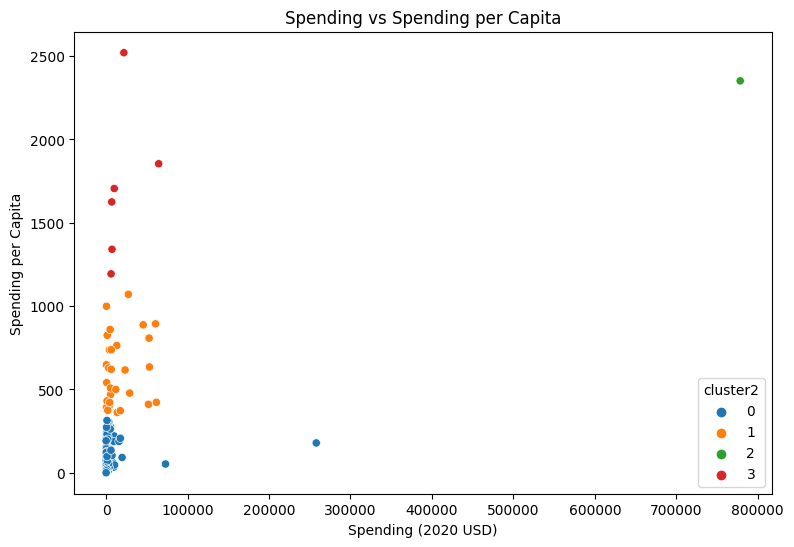

         Spending (2020 USD)                                              \
                       count           mean           std            min   
cluster2                                                                   
0                      111.0    4859.185065  25405.739131       8.622460   
1                       30.0   17077.591354  20583.053357     405.790494   
2                        1.0  778397.200000           NaN  778397.200000   
3                        6.0   19443.362047  22861.507114    6095.708713   

                                                                      \
                    25%            50%            75%            max   
cluster2                                                               
0            130.010211     382.464677    2297.032353  257973.429834   
1           2294.039665    5857.060906   26296.001003   61712.537169   
2         778397.200000  778397.200000  778397.200000  778397.200000   
3           7023.251766    8624.225

In [54]:
print("-- Q2.2 - Determine optimal k for spending --")

# select the variables
cols2 = ["Spending (2020 USD)", "Spending per Capita"]

# Normalize the variables
scaler = MinMaxScaler()
X2 = scaler.fit_transform(df[cols2])

# xreate scree plot
sse = []

for k in range(1, 11):
    km = KMeans(n_clusters=k, random_state=100, n_init=10)
    km.fit(X2)
    sse.append(km.inertia_)

plt.figure(figsize=(7, 5))
plt.plot(range(1, 11), sse, marker="o")
plt.xlabel("Number of Clusters (k)")
plt.ylabel("SSE")
plt.title("Scree Plot - Spending and Spending per Capita")
plt.xticks(range(1, 11))
plt.show()

# choose num clusters based on scree plot
k2 = 4

# run K-means
km2 = KMeans(n_clusters=k2, random_state=100, n_init=10)
df["cluster2"] = km2.fit_predict(X2)

# scatterplot
plt.figure(figsize=(9, 6))
sns.scatterplot(
    data=df,
    x="Spending (2020 USD)",
    y="Spending per Capita",
    hue="cluster2",
    palette="tab10"
)

plt.title("Spending vs Spending per Capita")
plt.xlabel("Spending (2020 USD)")
plt.ylabel("Spending per Capita")
plt.show()

# describe table by cluster
print(df.groupby("cluster2")[cols2].describe())

# average spending by cluster
print(df.groupby("cluster2")[cols2].mean())

# number of countries in each cluster
print(df["cluster2"].value_counts())

# find the United States
print(df[df["Country"].str.contains("United States", case=False, na=False)]
      [["Country", "cluster2"] + cols2])

# see which countries are in each cluster
for cluster in sorted(df["cluster2"].unique()):
    print("\nCluster", cluster)
    print(df[df["cluster2"] == cluster]["Country"].tolist())
    
text = "The clusters seem to be separated based on how much a country spends on its military and how much they spend per person. I feel like most countries with lower spending would be grouped together, and then countries with a huge military budget or high per-person spending would be in different clusters. The United States has one of the largest military budgets, so it makes sense for it to be towards the far right of the scatter plot and probably separated from all the other countries. I think, overall, this clustering really helps show the difference between the countries that spend a lot overall and countries that spend a lot relative to their specific population."

print("\n".join(textwrap.wrap(text, width=80)))

-- Q2.3 - Determine optimal k for government spending and GDP --


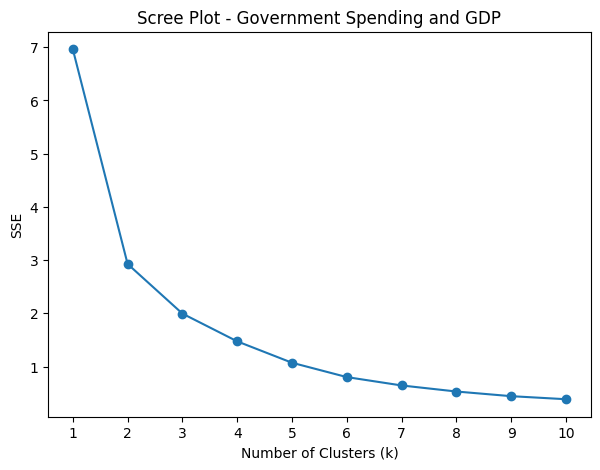

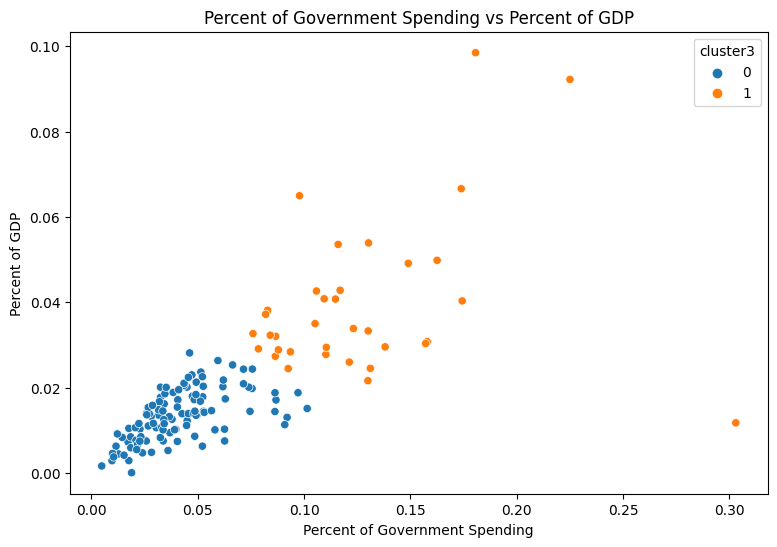

         Percent of Government Spending                                \
                                  count      mean       std       min   
cluster3                                                                
0                                 113.0  0.041394  0.020681  0.004896   
1                                  35.0  0.126456  0.046209  0.076005   

                                                 Percent of GDP            \
               25%       50%       75%       max          count      mean   
cluster3                                                                    
0         0.026783  0.038486  0.051496  0.101501          113.0  0.013481   
1         0.093093  0.116052  0.143584  0.303027           35.0  0.039433   

                                                                      
               std       min       25%       50%       75%       max  
cluster3                                                              
0         0.005966  0.000054  0.009

In [55]:
print("-- Q2.3 - Determine optimal k for government spending and GDP --")

# select the variables
cols3 = ["Percent of Government Spending", "Percent of GDP"]

# normalize the variables
scaler = MinMaxScaler()
X3 = scaler.fit_transform(df[cols3])

# create scree plot
sse = []

for k in range(1, 11):
    km = KMeans(n_clusters=k, random_state=100, n_init=10)
    km.fit(X3)
    sse.append(km.inertia_)

plt.figure(figsize=(7, 5))
plt.plot(range(1, 11), sse, marker="o")
plt.xlabel("Number of Clusters (k)")
plt.ylabel("SSE")
plt.title("Scree Plot - Government Spending and GDP")
plt.xticks(range(1, 11))
plt.show()

# choose number of clusters based on scree plot
k3 = 2

# run K-means
km3 = KMeans(n_clusters=k3, random_state=100, n_init=10)
df["cluster3"] = km3.fit_predict(X3)

# scatterplot
plt.figure(figsize=(9, 6))
sns.scatterplot(
    data=df,
    x="Percent of Government Spending",
    y="Percent of GDP",
    hue="cluster3",
    palette="tab10"
)

plt.title("Percent of Government Spending vs Percent of GDP")
plt.xlabel("Percent of Government Spending")
plt.ylabel("Percent of GDP")
plt.show()

# describe table by cluster
print(df.groupby("cluster3")[cols3].describe())

# average values by cluster
print(df.groupby("cluster3")[cols3].mean())

# number of countries in each cluster
print(df["cluster3"].value_counts())

# find the United States
print(df[df["Country"].str.contains("United States", case=False, na=False)]
      [["Country", "cluster3"] + cols3])

# see which countries are in each cluster
for cluster in sorted(df["cluster3"].unique()):
    print("\nCluster", cluster)
    print(df[df["cluster3"] == cluster]["Country"].tolist())
    
text = "This time, the clustering focused more on how much of a country's government spending and GDP goes towards its military, rather than the actual amount of money spent. I would expect the countries with higher percentages to group together, and countries with smaller percentages to group together. This was essentially the case I had with two clusters, since the elbow point was at k=2. A very interesting difference is that a country with a smaller military budget could still be in a high-spending cluster if a large percentage of its GDP or government spending goes towards the military. There is a core difference in what the clusters represent compared to the previous part. In part two, countries are grouped together based on the total spending and spending per person. In part three, they're grouped together based on the proportion of their resources that is devoted to the military. There is a difference between the total amount and the proportion. The United States seemed to stand out far more in Part 2 because of its massive total military budget. But in Part 3, we see that the US blends in more with the higher spending group."

print("\n".join(textwrap.wrap(text, width=80)))

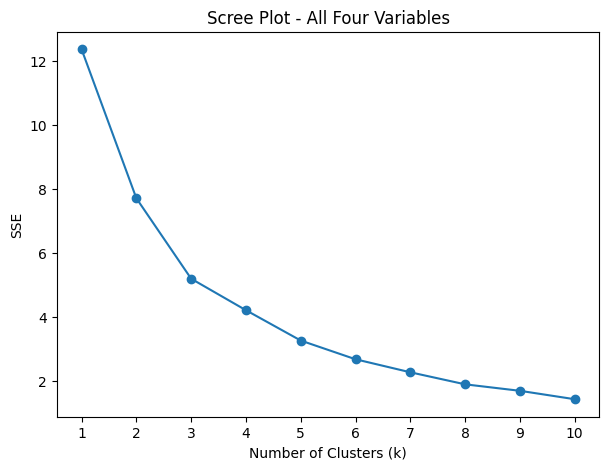

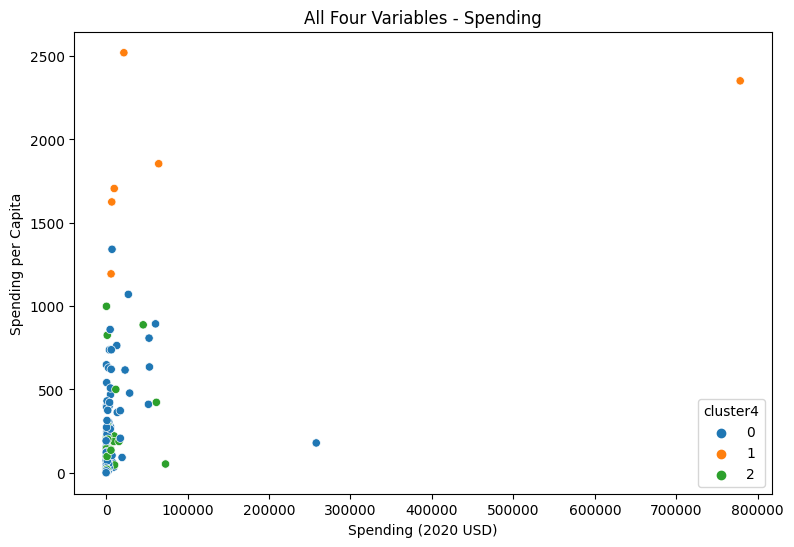

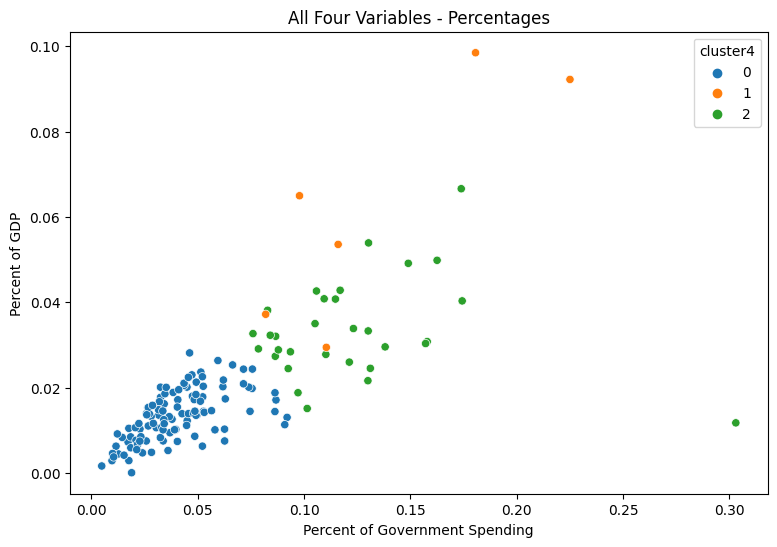

         Spending (2020 USD)                                             \
                       count           mean            std          min   
cluster4                                                                  
0                      111.0    7086.472777   26479.379918     8.622460   
1                        6.0  147964.582042  309635.189564  6095.708713   
2                       31.0    8786.086602   17901.909108   162.373364   

                                                                  \
                  25%           50%           75%            max   
cluster4                                                           
0          130.010211    567.650747   3910.107493  257973.429834   
1         7700.424616  15897.570598  53872.942442  778397.200000   
2          467.787851   1404.787234   7739.166193   72937.064048   

         Spending per Capita               ... Percent of Government Spending  \
                       count         mean  ...             

In [ ]:
print("-- Q2.4 - Determine optimal k for all four variables --")

# select all 4 variables
cols4 = [
    "Spending (2020 USD)",
    "Spending per Capita",
    "Percent of Government Spending",
    "Percent of GDP"
]

# normalize the variables
scaler = MinMaxScaler()
X4 = scaler.fit_transform(df[cols4])

# create scree plot
sse = []

for k in range(1, 11):
    km = KMeans(n_clusters=k, random_state=100, n_init=10)
    km.fit(X4)
    sse.append(km.inertia_)

plt.figure(figsize=(7, 5))
plt.plot(range(1, 11), sse, marker="o")
plt.xlabel("Number of Clusters (k)")
plt.ylabel("SSE")
plt.title("Scree Plot - All Four Variables")
plt.xticks(range(1, 11))
plt.show()

# choose number of clusters based on scree plot
k4 = 3

# run K-means
km4 = KMeans(n_clusters=k4, random_state=100, n_init=10)
df["cluster4"] = km4.fit_predict(X4)

# scatterplot for spending variables
plt.figure(figsize=(9, 6))
sns.scatterplot(
    data=df,
    x="Spending (2020 USD)",
    y="Spending per Capita",
    hue="cluster4",
    palette="tab10"
)

plt.title("All Four Variables - Spending")
plt.xlabel("Spending (2020 USD)")
plt.ylabel("Spending per Capita")
plt.show()

# scatterplot for percentage variables
plt.figure(figsize=(9, 6))
sns.scatterplot(
    data=df,
    x="Percent of Government Spending",
    y="Percent of GDP",
    hue="cluster4",
    palette="tab10"
)

plt.title("All Four Variables - Percentages")
plt.xlabel("Percent of Government Spending")
plt.ylabel("Percent of GDP")
plt.show()

# describe table by cluster
print(df.groupby("cluster4")[cols4].describe())

# average values by cluster
print(df.groupby("cluster4")[cols4].mean())

# number of countries in each cluster
print(df["cluster4"].value_counts())

# find the United States
print(df[df["Country"].str.contains("United States", case=False, na=False)]
      [["Country", "cluster4"] + cols4])

# compare clusters from Parts 2 and 4
print("\nPart 2 vs Part 4:")
print(pd.crosstab(df["cluster2"], df["cluster4"]))

# compare clusters from Parts 3 and 4
print("\nPart 3 vs Part 4:")
print(pd.crosstab(df["cluster3"], df["cluster4"]))

# see which countries are in each cluster
for cluster in sorted(df["cluster4"].unique()):
    print("\nCluster", cluster)
    print(df[df["cluster4"] == cluster]["Country"].tolist())

text = "By using all four variables, we have a lot more to work with. Instead of only looking at the size of the military budget or the percentage of a country's resources spent on military, it considers both. I would expect a few countries to change their clusters compared to parts two and three, since the algorithm is considering more characteristics. For example, if there's a country with a large military budget, it might not necessarily have a high percentage of GDP spent on defense. I think using all four variables could give a more complete picture of military spending, but the clusters may also become harder to interpret because there are more factors involved."

print("\n".join(textwrap.wrap(text, width=80)))

In [61]:
print("-- Q2.5 - kMC Useful Patterns --")

text = "I certainly think that k-means clustering was useful for finding patterns in military spending. It really showed that countries can have very different spending patterns based on what variables we specifically take a look at. Some countries may spend a great amount of money overall. Other countries may spend a large percentage of their GDP or government budget on defense. For example, a country with a massive amount of money could spend a very large amount of money on the military, but it only amounts to a very small proportion of their overall spending. On the other hand, a government with a much lower GDP or government budget may spend a great portion of that budget on the military. We see a great example of this with China and Oman, where China substantially far more on its military than Oman, but Oman devotes a much larger proportion of its GDP and government budget to defense. It's also interesting to see how changing the variables can change how the countries are grouped together. This shows that there isn't necessarily one single way to categorize military spending. Overall, I really find k-means a useful way to identify similarities and differences between countries, but it doesn't really explain why countries do spend the amounts that they might."

print("\n".join(textwrap.wrap(text, width=80)))

-- Q2.5 - kMC Useful Patterns --
I certainly think that k-means clustering was useful for finding patterns in
military spending. It really showed that countries can have very different
spending patterns based on what variables we specifically take a look at. Some
countries may spend a great amount of money overall. Other countries may spend a
large percentage of their GDP or government budget on defense. For example, a
country with a massive amount of money could spend a very large amount of money
on the military, but it only amounts to a very small proportion of their overall
spending. On the other hand, a government with a much lower GDP or government
budget may spend a great portion of that budget on the military. We see a great
example of this with China and Oman, where China substantially far more on its
military than Oman, but Oman devotes a much larger proportion of its GDP and
government budget to defense. It's also interesting to see how changing the
variables can change how t

## *Phase 2: AI-assisted Revision
Keep Phase 1 frozen.

- **Phase 1 commit SHA ID:** [To be provided]
- **AI tool and model used:** [To be provided]

### *Prompts used

1. [Paste prompt]
2. [Paste follow-up prompt]

### *AI-proposed changes


[Paste the AI's concise numbered list verbatim.]

1. ...
2. ...

### *Evaluation of AI suggestions


| Change | Decision | Reason and verification |
|---|---|---|
| 1 | Accept / modify / reject | ... |
| 2 | Accept / modify / reject | ... |

### *AI-assisted solution in full
After the evaluation of AI suggestions, incorporate the accepted revisions into your Phase 1 solution and provide the final Phase 2 solution in full in the following cells.

In [ ]:
# Your Phase 2 solution to the problem goes here.


### *Reflection on AI assistance
In your own words without generative AI.

[In 150–300 words, describe the main improvements, AI mistakes or limitations, how the final solution was verified, and any remaining concerns.]